# EDA e diagnóstico de qualidade (ICRA) — dataset de referência

**Tech Challenge Fase 4 · Etapa 1.** Este notebook explora o dataset de referência
sintético (`data/reference/credit_ref.parquet`, ADR 001) e mostra o contrato de dados
(ADR 002) aprovando a referência e bloqueando o lote corrompido.

Estrutura: (1) carregamento · (2) perfil ICRA · (3) distribuições por alvo ·
(4) correlações · (5) taxa base por segmento · (6) atributos sensíveis fora do modelo ·
(7) contrato de dados em ação.

> Privacidade: nenhuma célula exibe `id_cliente` em claro; amostras passam por
> `pseudonymize_ids` (HMAC-SHA-256).

In [1]:
import warnings

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

from credit_sentinel.contracts.privacy_sanitizer import pseudonymize_ids
from credit_sentinel.contracts.schema import RULES, build_inference_schema, build_reference_schema
from credit_sentinel.contracts.validator import (
    BatchContext,
    ContractViolationError,
    ValidationPolicy,
    validate_batch,
)
from credit_sentinel.data import dictionary as dd
from credit_sentinel.ml.features import MODEL_FEATURES
from credit_sentinel.settings import Settings

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
settings = Settings(_env_file=None, project_root=Settings().project_root)

## 1. Carregamento e separação referência × lote corrompido

In [2]:
reference = pd.read_parquet(settings.reference_dir / "credit_ref.parquet")
bad_batch = pd.read_parquet(settings.corrupted_dir / "bad_batch.parquet")
salt = settings.pii_salt.get_secret_value()
print(f"referência: {reference.shape[0]:,} linhas × {reference.shape[1]} colunas")
print(f"lote corrompido: {bad_batch.shape[0]:,} linhas × {bad_batch.shape[1]} colunas")
print(f"taxa base de inadimplência: {reference[dd.TARGET].mean():.2%}")
pseudonymize_ids(reference, salt=salt).head(3)

referência: 12,000 linhas × 18 colunas
lote corrompido: 600 linhas × 19 colunas
taxa base de inadimplência: 6.45%


,id_cliente_hash,data_referencia,idade,renda_mensal,score_bureau,taxa_endividamento,utilizacao_credito,tempo_emprego_meses,qtd_parcelas_atraso_12m,valor_emprestimo,prazo_meses,valor_parcela,situacao_emprego,finalidade_credito,possui_imovel,genero,regiao,inadimplente
0,28f98a7f8a517b25f991cda1679a9583df1600122752b5...,2026-02-16,35,2613.26,680,0.4647,0.6140,19,1,3490.35,24,195.16,CLT,outros,False,F,Sudeste,0
1,5b546a8518e56d110e08b5544cb478156da7bed01e1433...,2026-01-27,47,6637.33,764,0.3136,0.1680,42,0,6978.88,60,225.79,servidor_publico,reforma,True,F,Sudeste,0
2,5f0da72c3cda12a5688f49351bb8b0b421396e7953c906...,2026-03-26,32,1844.67,623,0.6288,0.3696,136,1,19795.14,24,1106.80,CLT,consolidacao_dividas,False,F,Sudeste,0


## 2. Perfil ICRA

| Dimensão | Pergunta | Evidência abaixo |
| :--- | :--- | :--- |
| **I**ntegridade | Colunas e tipos são os esperados? | `dtypes` × dicionário |
| **C**ompletude | Há valores ausentes? | matriz `missingno` |
| **R**azoabilidade | Os valores são plausíveis? | estatísticas descritivas |
| **A**curácia | Os valores respeitam o domínio? | contagem de violações por regra |

In [3]:
expected = {spec.name: spec.dtype for spec in dd.COLUMN_SPECS}
integrity = pd.DataFrame({
    "esperado": pd.Series(expected),
    "referência": reference.dtypes.astype(str),
    "lote corrompido": bad_batch.dtypes.astype(str).reindex(list(expected) + ["cpf"]),
})
integrity

,esperado,referência,lote corrompido
cpf,NaN,NaN,object
data_referencia,datetime64[ns],datetime64[ns],datetime64[ns]
finalidade_credito,string,object,object
genero,string,object,object
id_cliente,string,object,object
idade,int64,int64,int64
inadimplente,int64,int64,int64
possui_imovel,bool,bool,bool
prazo_meses,int64,int64,int64
qtd_parcelas_atraso_12m,int64,int64,int64


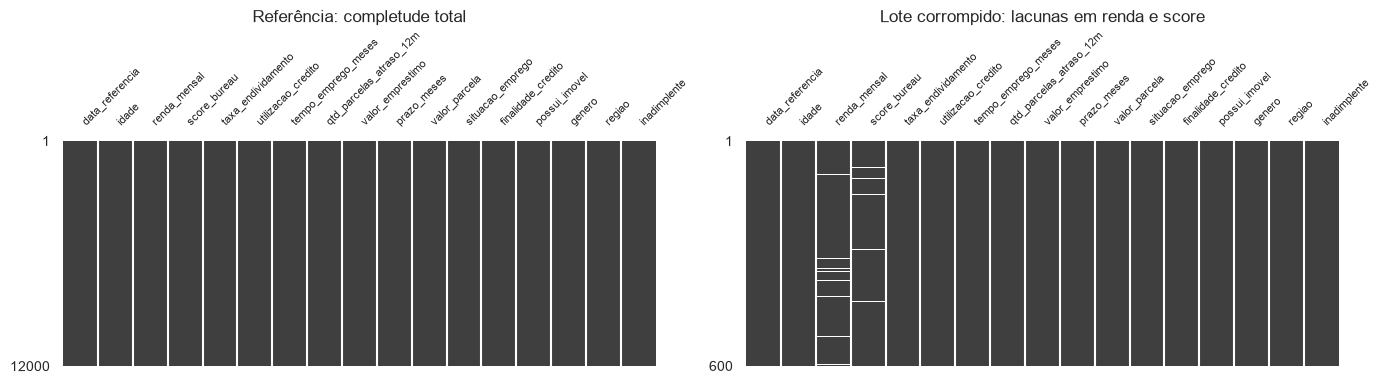

nulos por coluna (lote corrompido):
id_cliente       6
renda_mensal    24
score_bureau    18
dtype: int64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
msno.matrix(reference.drop(columns=[dd.ID_COLUMN]), ax=axes[0], sparkline=False, fontsize=8)
axes[0].set_title("Referência: completude total")
msno.matrix(bad_batch.drop(columns=[dd.ID_COLUMN, "cpf"]), ax=axes[1], sparkline=False, fontsize=8)
axes[1].set_title("Lote corrompido: lacunas em renda e score")
plt.tight_layout()
plt.show()
print("nulos por coluna (lote corrompido):")
print(bad_batch.isna().sum()[lambda s: s > 0])

In [5]:
reference[dd.NUMERIC_COLUMNS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
idade,12000.0,43.066,12.029,18.000,34.000,43.000,51.000,85.000
renda_mensal,12000.0,4152.251,2749.872,800.000,2297.870,3493.390,5248.622,47584.230
score_bureau,12000.0,650.252,133.751,139.000,561.000,649.000,741.000,1000.000
taxa_endividamento,12000.0,0.372,0.177,0.023,0.236,0.349,0.492,0.945
utilizacao_credito,12000.0,0.400,0.242,0.000,0.216,0.386,0.567,1.000
tempo_emprego_meses,12000.0,64.942,50.683,0.000,28.000,55.000,91.000,366.000
qtd_parcelas_atraso_12m,12000.0,0.309,0.635,0.000,0.000,0.000,0.000,8.000
valor_emprestimo,12000.0,13467.246,9286.937,1000.000,7088.290,11119.625,17102.458,103755.540
prazo_meses,12000.0,27.687,14.894,6.000,12.000,24.000,36.000,60.000
valor_parcela,12000.0,856.010,672.242,43.200,400.768,664.230,1107.728,8342.480


## 3. Distribuições das principais features por alvo

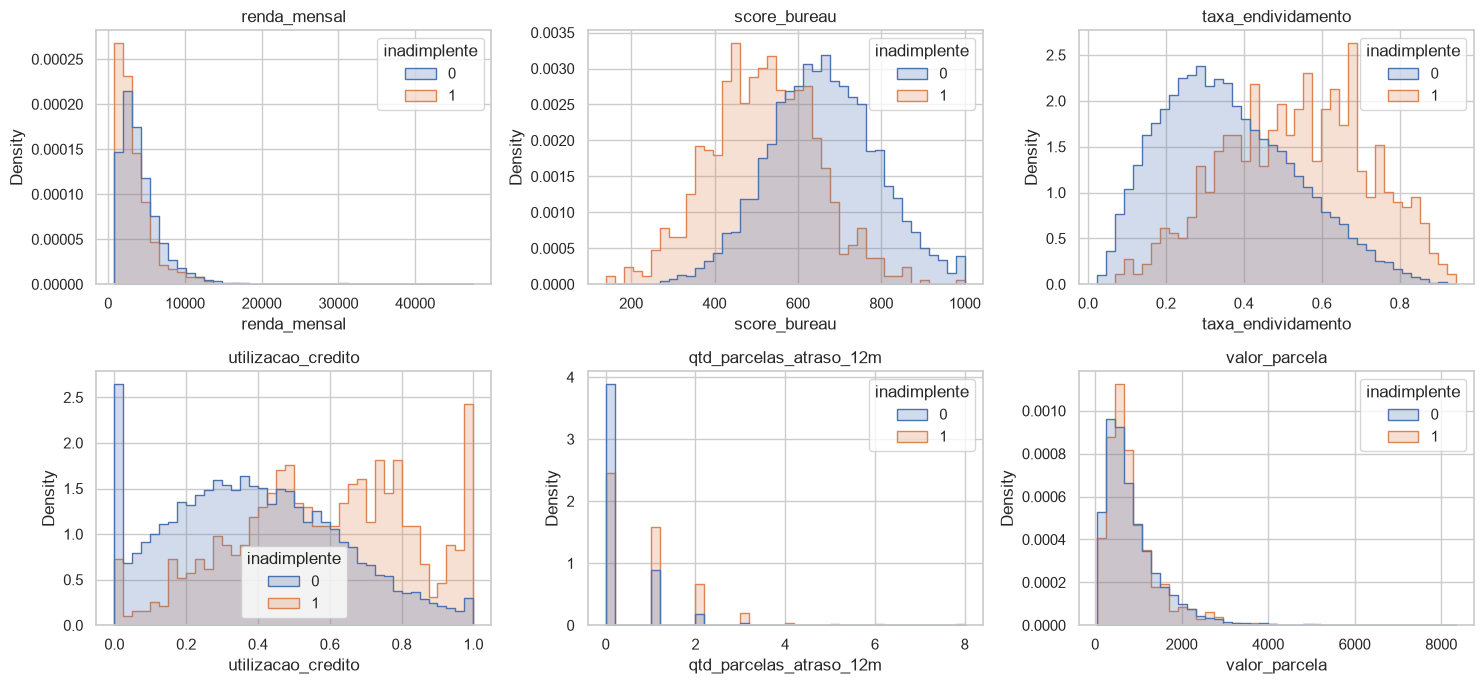

In [6]:
features = ["renda_mensal", "score_bureau", "taxa_endividamento",
            "utilizacao_credito", "qtd_parcelas_atraso_12m", "valor_parcela"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, column in zip(axes.ravel(), features, strict=True):
    sns.histplot(data=reference, x=column, hue=dd.TARGET, stat="density",
                 common_norm=False, bins=40, element="step", ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

## 4. Correlações entre features numéricas e o alvo

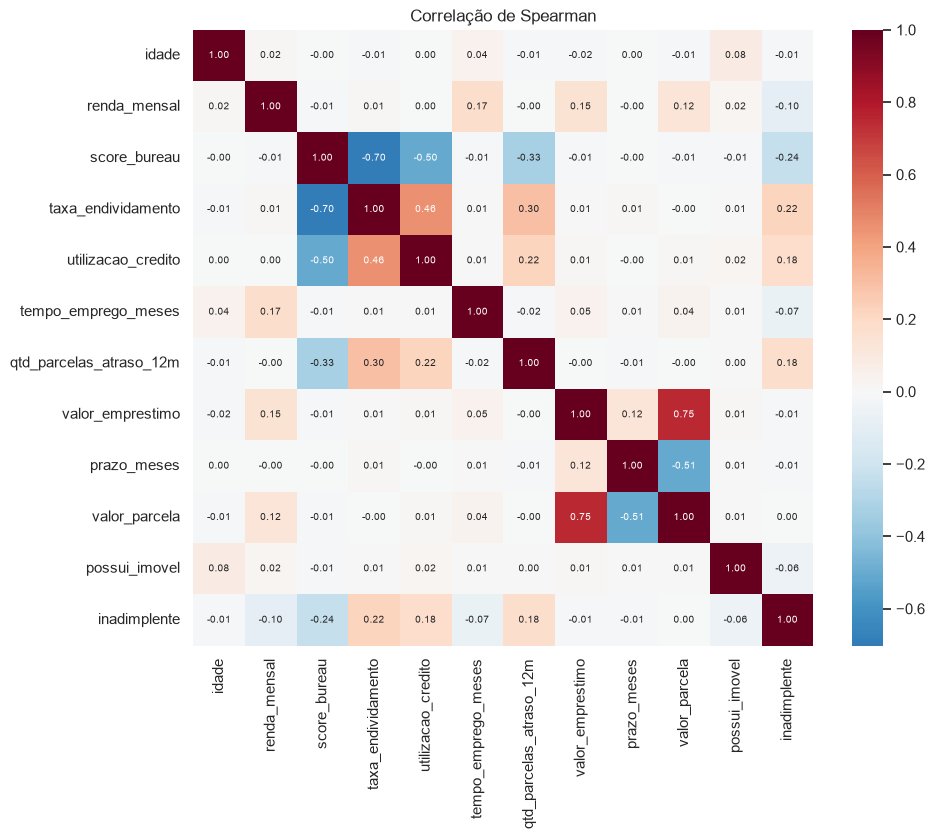

In [7]:
numeric = reference[dd.NUMERIC_COLUMNS + [dd.TARGET]].astype(float)
plt.figure(figsize=(10, 8))
sns.heatmap(numeric.corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Correlação de Spearman")
plt.show()

## 5. Taxa base por situação de emprego e faixa de score

In [8]:
by_job = reference.groupby("situacao_emprego")[dd.TARGET].agg(["mean", "size"])
bands = pd.cut(reference["score_bureau"], bins=[0, 450, 550, 700, 850, 1000], include_lowest=True)
by_score = reference.groupby(bands, observed=True)[dd.TARGET].agg(["mean", "size"])
display(by_job.rename(columns={"mean": "taxa", "size": "clientes"}).style.format({"taxa": "{:.2%}"}))
display(by_score.rename(columns={"mean": "taxa", "size": "clientes"}).style.format({"taxa": "{:.2%}"}))

,taxa,clientes
situacao_emprego,,
CLT,5.34%,6216
aposentado,5.46%,1080
autonomo,5.94%,2642
desempregado,18.55%,857
servidor_publico,5.56%,1205


,taxa,clientes
score_bureau,,
"(-0.001, 450.0]",29.58%,825
"(450.0, 550.0]",12.10%,1867
"(550.0, 700.0]",5.00%,5079
"(700.0, 850.0]",1.29%,3409
"(850.0, 1000.0]",0.73%,820


## 6. Atributos sensíveis fora do modelo

`genero` e `regiao` existem apenas para a auditoria de fairness (Etapa 4). O conjunto de
features do modelo é verificado abaixo; diferenças de taxa por grupo surgem só de forma
indireta (via renda), porque o processo gerador não usa esses atributos no logit.

In [9]:
assert set(dd.SENSITIVE_COLUMNS).isdisjoint(MODEL_FEATURES)
print("features do modelo:", MODEL_FEATURES)
reference.groupby(["genero"])[dd.TARGET].mean().to_frame("taxa").join(
    reference.groupby("genero")["renda_mensal"].median().to_frame("renda mediana"))

features do modelo: ['idade', 'renda_mensal', 'score_bureau', 'taxa_endividamento', 'utilizacao_credito', 'tempo_emprego_meses', 'qtd_parcelas_atraso_12m', 'valor_emprestimo', 'prazo_meses', 'valor_parcela', 'possui_imovel', 'comprometimento_renda', 'situacao_emprego', 'finalidade_credito']


,taxa,renda mediana
genero,,
F,0.064077,3513.335
M,0.064937,3478.405


## 7. Contrato de dados em ação

12 regras (R01 a R12). A referência deve passar em todas; o lote corrompido deve ser
**bloqueado** por violação estrutural, com inventário completo das violações.

In [10]:
pd.DataFrame([{"regra": r.id, "dimensão": r.dimension, "severidade": r.severity,
               "descrição": r.description} for r in RULES])

,regra,dimensão,severidade,descrição
0,R01,Integridade,estrutural,Schema estrito: conjunto exato de colunas e ti...
1,R02,Unicidade,estrutural,"id_cliente único, não nulo e no formato CLI-XX..."
2,R03,Completude,linha,"Campos críticos sem nulos (renda, score, idade..."
3,R04,Acurácia,linha,Idade entre 18 e 100 anos
4,R05,Acurácia,linha,Renda mensal positiva e até R$ 1.000.000
5,R06,Acurácia,linha,Score de bureau entre 0 e 1000
6,R07,Acurácia,linha,Taxa de endividamento e utilização de crédito ...
7,R08,Acurácia,linha,Categorias dentro dos domínios e prazo/alvo no...
8,R09,Razoabilidade,linha,Valores da operação positivos e contadores em ...
9,R10,Consistência,linha,Parcela não pode exceder a renda mensal


In [11]:
policy = ValidationPolicy()
_, ref_report = validate_batch(reference, schema=build_reference_schema(), policy=policy,
                               context=BatchContext(batch_name="credit_ref", run_id="eda"))
print(ref_report.decision, "· rejeitadas:", ref_report.rejected_records)

try:
    validate_batch(bad_batch, schema=build_inference_schema(), policy=policy,
                   context=BatchContext(batch_name="bad_batch", run_id="eda"))
except ContractViolationError as error:
    bad_report = error.report
print(bad_report.decision, "·", bad_report.blocked_reason)
pd.DataFrame([v.model_dump(exclude={"sample_index"}) for v in bad_report.violations])

SUCCESS · rejeitadas: 0
BLOCKED · violação estrutural (R01, R02): lote bloqueado


,rule_id,column,check,n_failures
0,R01,cpf,column_in_schema,1
1,R01,score_bureau,dtype('int64'),18
2,R02,id_cliente,field_uniqueness,36
3,R02,id_cliente,not_nullable,6
4,R03,renda_mensal,not_nullable,24
5,R03,score_bureau,not_nullable,18
6,R04,idade,R04 · idade fora da faixa,30
7,R07,taxa_endividamento,R07 · taxa_endividamento fora da faixa,12
8,R08,situacao_emprego,R08 · situacao_emprego fora do domínio,18
9,R10,None,R10 · valor_parcela <= renda_mensal,12


## Conclusões

- A referência é íntegra e completa (0 nulos, tipos exatos) e passa nas 12 regras.
- O lote corrompido é bloqueado por violações estruturais (coluna `cpf` não prevista,
  ids nulos/duplicados e tipo de `score_bureau`), e o inventário lista todas as
  anomalias de linha, sem imputação.
- Score de bureau, atrasos e utilização concentram o sinal de risco, coerente com o
  processo gerador e com a importância de features do baseline.